# Lab 12: Statistical error estimation

- Every number that comes out of a Monte Carlo simulation is an average over samples.
- From here on the course runs on such averages: the Ising magnetization from Lab 11, the path-integral averages of next week, and your final projects.
- A Monte Carlo result without an error bar cannot be compared with anything. Today we learn to compute one honestly.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from numba import njit
from scipy.stats import norm
from IPython.display import HTML

plt.rcParams.update({
    "font.size": 13,
    "figure.figsize": (6.2, 3.5),
    "figure.dpi": 100,
    "figure.constrained_layout.use": True,
})
J = 1.0
KB = 1.0


def show_lattice(axis, lattice, title):
    image = axis.imshow(lattice, cmap="RdYlBu", vmin=-1, vmax=1)
    axis.set(title=title, xticks=[], yticks=[])
    return image


def plot_resamples(replicates, estimate, error, xlabel, label):
    fig, ax = plt.subplots()
    ax.hist(replicates, bins=40, density=True, color="#9fc9d3", label=label)
    top = ax.get_ylim()[1]
    ax.errorbar(estimate, 0.9 * top, xerr=error, fmt="o", color="#a54632", capsize=5,
                elinewidth=2, capthick=2, label="estimate ± jackknife error")
    ax.set(xlabel=xlabel, ylabel="Density")
    ax.legend(fontsize=10)
    plt.show()

We'll use NumPy for the arrays, Matplotlib for the plots, SciPy for one Gaussian curve, and Numba to compile the loops. Two plotting helpers live here as well: `show_lattice` draws a lattice with blue for $+1$ and red for $-1$, and `plot_resamples` draws a histogram of resampled values with an error bar on top. Run the cells in order; later cells use the functions we define along the way.

## Why this matters

- In Assignment 3 you will compute $\langle x^2\rangle$ for the harmonic oscillator by path-integral Monte Carlo and compare it with the exact value $\tfrac12\coth(\beta/2)$.
- Suppose you get $0.63\pm0.02$ and the exact value is $0.656$. Agreement, or a bug?
- The answer depends entirely on whether $\pm0.02$ is right.
- Getting the $\pm$ right turns out to be harder than the familiar $s/\sqrt N$, which comes out too small here, often by a lot.
- $s/\sqrt N$ is for uncorrelated measurements, which was not the case for our Ising example yesterday.

## Yesterday's sampler

- Lab 11's Metropolis update, compiled with Numba and split into four small functions over the next three slides: the energy change, the accept-or-reject step, one sweep, and the loop that records $m$ and saves snapshots of the lattice.
- Two reminders:
  - One **sweep** is $N^2$ attempted spin flips, one per site on average.
  - **Burn-in** is the sweeps we throw away at the start, before the lattice has forgotten that it began with every spin up.
- The compiled functions take a `distribution`: NumPy's random generator, made from a seed so that a run is reproducible.
- Everything here is from Lab 11; only the packaging is new.

## The energy change of one flip

- Flipping the spin at `(row, column)` changes only its four bonds.
- $\Delta E = 2J\,\sigma_{ij}\sum_{\mathrm{nbrs}}\sigma$: positive when the spin agrees with most of its neighbors, negative when it disagrees.
- The `% lattice_size` wraps the neighbor index around the edges: periodic boundaries, as in Lab 11.

In [ ]:
@njit
def flip_energy(spins, row, column):
    lattice_size = spins.shape[0]
    neighbors = (spins[(row - 1) % lattice_size, column] + spins[(row + 1) % lattice_size, column]
                 + spins[row, (column - 1) % lattice_size] + spins[row, (column + 1) % lattice_size])
    return 2 * J * spins[row, column] * neighbors

Nothing is flipped here: the function only reports what a flip at `(row, column)` would cost.

## Accept or reject

- Pick a site at random and ask `flip_energy` what the flip would cost.
- Energy falls or stays the same: flip.
- Energy rises: flip with probability $e^{-\Delta E/(k_{\mathrm B}T)}$, by comparing a uniform random number from `distribution` with it.
- A rejected proposal leaves the lattice unchanged but still counts as an attempt.

In [ ]:
@njit
def attempt_flip(spins, temperature, distribution):
    lattice_size = spins.shape[0]
    row, column = distribution.integers(0, lattice_size, size=2)
    delta_energy = flip_energy(spins, row, column)
    if delta_energy <= 0 or distribution.random() < np.exp(-delta_energy / (KB * temperature)):
        spins[row, column] *= -1

The `or` short-circuits, so the uniform random number is drawn only when the energy would rise.

## Sweeps and the record of $m$

- `one_sweep` makes $N^2$ attempts; sites are chosen at random, so some are tried more than once and some not at all.
- `ising_sweeps` repeats that, records the magnetization per spin $m$ after every sweep, and saves a snapshot of the whole lattice every `record_every` sweeps.
- `run_ising` starts from all spins up, makes the `distribution` from the seed, and returns the final lattice, the history of $m$, and the stack of snapshots.

In [ ]:
@njit
def one_sweep(spins, temperature, distribution):
    lattice_size = spins.shape[0]
    for _ in range(lattice_size * lattice_size):
        attempt_flip(spins, temperature, distribution)


@njit
def ising_sweeps(spins, temperature, n_sweeps, distribution, record_every):
    lattice_size = spins.shape[0]
    magnetization = np.empty(n_sweeps + 1)
    snapshots = np.empty((n_sweeps // record_every + 1, lattice_size, lattice_size), dtype=np.int64)
    magnetization[0] = spins.mean()
    snapshots[0, :, :] = spins
    for sweep in range(1, n_sweeps + 1):
        one_sweep(spins, temperature, distribution)
        magnetization[sweep] = spins.mean()
        if sweep % record_every == 0:
            snapshots[sweep // record_every, :, :] = spins
    return magnetization, snapshots


def run_ising(temperature, lattice_size, n_sweeps, seed, record_every):
    spins = np.ones((lattice_size, lattice_size), dtype=np.int64)
    distribution = np.random.default_rng(seed)
    magnetization, snapshots = ising_sweeps(spins, temperature, n_sweeps, distribution, record_every)
    return spins, magnetization, snapshots

The first call compiles all four functions, which takes a few seconds; later runs reuse the compiled code. A snapshot is the full $N\times N$ array of spins, so `record_every` keeps the memory use small.

## A run at $T = 2.7$

- A $24\times24$ lattice, 1,024 sweeps of burn-in, then 16,384 sweeps with $m$ recorded after each one.
- A snapshot of the lattice every 16 sweeps. Three of them are shown under the trace: the all-up start, the end of burn-in, and the end of the run.
- The trace shows the first 1,500 recorded sweeps.

In [ ]:
N_LATTICE, BURNIN, SWEEPS, RECORD_EVERY = 24, 1024, 16_384, 16
T = 2.7
lattice, m_history, snapshots = run_ising(T, N_LATTICE, BURNIN + SWEEPS, seed=142, record_every=RECORD_EVERY)
m_run = m_history[BURNIN + 1:]

fig = plt.figure(figsize=(6.4, 5.0))
layout = fig.add_gridspec(2, 3, height_ratios=(1.15, 1))
trace = fig.add_subplot(layout[0, :])
trace.plot(m_run[:1500], color="#007c91", linewidth=0.9)
trace.set(xlabel="Sweep after burn-in", ylabel="Magnetization per spin m", title=f"T = {T}")
for column, (sweep, name) in enumerate([(0, "start"), (BURNIN, "end of burn-in"), (BURNIN + SWEEPS, "end of run")]):
    snapshot = snapshots[sweep // RECORD_EVERY]
    show_lattice(fig.add_subplot(layout[1, column]), snapshot, f"{name}: m = {snapshot.mean():+.2f}")
plt.show()
print(f"Mean m over {len(m_run):,} sweeps: {m_run.mean():+.4f}")
print(f"Standard deviation of m:      {m_run.std():.4f}")

The trace wanders: $m$ stays near one value for tens of sweeps before drifting away. This is the data we want an error bar for. The snapshots show what burn-in is for: the all-up start looks nothing like a typical configuration at $T=2.7$, while the end of burn-in and the end of the run look alike.

## Two consecutive sweeps

- Run one more sweep from the final lattice and compare it with the lattice before.
- The outlined sites are the spins that flipped.

In [ ]:
before = lattice.copy()
ising_sweeps(lattice, T, 1, np.random.default_rng(7), record_every=1)
changed = np.argwhere(lattice != before)

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.4))
show_lattice(axes[0], before, f"After sweep t: m = {before.mean():+.3f}")
show_lattice(axes[1], lattice, f"After sweep t + 1: m = {lattice.mean():+.3f}")
for row, column in changed:
    axes[1].add_patch(plt.Rectangle((column - 0.5, row - 0.5), 1, 1, fill=False,
                                    edgecolor="#e0a53a", linewidth=1.5))
plt.show()
print(f"{len(changed)} of {N_LATTICE**2} spins flipped; m changed by {lattice.mean() - before.mean():+.4f}")

Most of the lattice is unchanged, so the next measurement of $m$ is nearly a repeat of the last one. Two consecutive measurements carry much less than two measurements' worth of information.

## What an error bar means

- Rerun the simulation with a different seed and the mean comes out slightly different.
- Do it many times and the means pile up in a narrow heap.
- **Standard error:** the width of that heap, so how far the mean of one run typically lands from the true value.
- **Standard deviation** $s$: how far individual values spread within one run. Not the same thing.
- We want the first one, from a single run, because we can't afford to rerun everything many times.

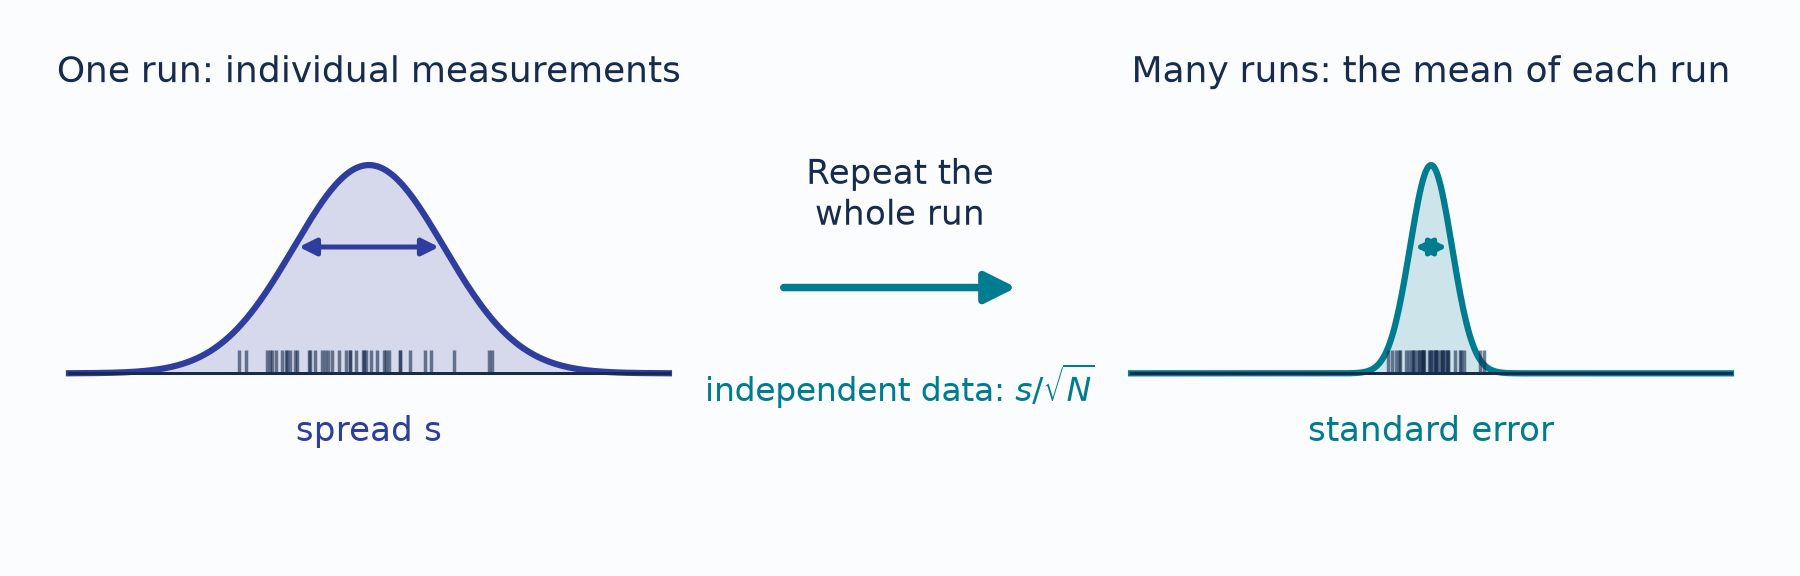

## The question

The run gives 16,384 values of $m$. The usual error bar on their mean divides the spread by $\sqrt N$:

$$\operatorname{SE}(\bar m)\stackrel{?}{=}\frac{s}{\sqrt N}.$$

- That formula assumes each measurement is a fresh draw that knows nothing about the one before it.
- Ours are not like that: a measurement is mostly a copy of the last one, because only a few spins flipped in between.
- Measurements that remember each other are **correlated**.
- The formula counts 16,384 fresh draws when we have far fewer, so it comes out too small.
- How much too small is the subject of this lab.

## The plan

Four questions, in order:

1. How long does the memory last? That is the **autocorrelation**.
2. How many fresh draws is our run worth? That is the **effective number of measurements**.
3. Can we get the error bar without measuring the memory at all? That is **blocking**.
4. What about a result that isn't a plain average? That is the **jackknife** and the **bootstrap**.

- We'll answer each one on a toy model whose right answer we know.
- Then all of it on yesterday's Ising run. Next week, on the path integral.

## Why a toy model?

- To test an error bar we need data whose true mean and true uncertainty are known.
- The Ising run can't tell us that.
- So we'll build the simplest model that shares its key feature, memory, and keep the Ising data for the end.

## Build a sequence with memory

- Start from independent Gaussian noise $\epsilon_t$.
- Each new value keeps a fraction $r$ of the previous value and adds fresh noise:

$$x_t = r\,x_{t-1} + \sqrt{1-r^2}\,\epsilon_t,\qquad \epsilon_t\sim\mathcal N(0,1).$$

- The square root keeps the variance at 1 for every $r$, and the mean is 0.
- Like the Ising update, the next value depends only on the current one: a **Markov chain**.
- This is our toy model for the rest of the lab.

## The generator

- One line per step: keep a fraction $r$ of the old value, add fresh noise.
- `distribution` is the random generator again, made from a seed by the caller; `distribution.normal()` draws one $\epsilon_t$.
- The name: statisticians call this rule **AR(1)**, *autoregressive of order 1*, because each value is regressed on the one before it; *stationary* because the first value is drawn from the same distribution as all the others.

In [ ]:
@njit
def stationary_ar1(n_values, r, distribution):
    x = np.empty(n_values)
    x[0] = distribution.normal()
    for t in range(1, n_values):
        x[t] = r * x[t - 1] + np.sqrt(1 - r**2) * distribution.normal()
    return x

Because the first value already has the right distribution, there is no burn-in to discard. That is the one luxury this toy has over the Ising chain.

## Three memories from the same noise

The same seed, so the same noise, with $r=0$, $0.5$, and $0.9$.

In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(6.2, 4.4), sharex=True)
for axis, r_value in zip(axes, (0.0, 0.5, 0.9)):
    axis.plot(stationary_ar1(150, r_value, np.random.default_rng(142)), color="#007c91")
    axis.set(ylabel=f"r = {r_value}", ylim=(-3.5, 3.5))
axes[-1].set(xlabel="Measurement index t")
plt.show()

- With $r=0$ every value is independent.
- With $r=0.9$ a high value is usually followed by another high value, like the Ising trace.
- All three have the same distribution of values, mean 0 and spread 1, so their histograms look alike. What differs is the **order**: which values tend to follow which in time.

## The sequence for the rest of the lab

- A correlated sequence with $r=0.9$ and 32,768 values, from seed 142.

In [ ]:
N = 32_768
r = 0.9
x = stationary_ar1(N, r, np.random.default_rng(142))
print(f"r = {r}: mean {x.mean():+.3f}, standard deviation {x.std():.3f}")

Mean 0 and spread 1, as designed. Everything that follows is about how far that mean can be trusted.

## Same histogram, different order

- Shuffle the sequence: the same 32,768 numbers in a random order.
- Left: the first 200 values, in the original order and shuffled. Middle: the two histograms, identical because the numbers are.
- Right: the **running mean**, the mean of the first $t$ values, for both orders. `running_mean` keeps a running total and divides by the count.

In [ ]:
@njit
def running_mean(values):
    means = np.empty(len(values))
    total = 0.0
    for t in range(len(values)):
        total += values[t]
        means[t] = total / (t + 1)
    return means

In [ ]:
shuffled = np.random.default_rng(1).permutation(x)

fig, axes = plt.subplots(1, 3, figsize=(7.6, 3.0))
axes[0].plot(shuffled[:200], color="#8a97a6", alpha=0.8, label="shuffled")
axes[0].plot(x[:200], color="#007c91", label="original order")
axes[0].set(xlabel="Measurement index t", ylabel="x")
axes[0].legend(fontsize=9)
bins = np.linspace(-4, 4, 41)
axes[1].hist(shuffled, bins=bins, density=True, histtype="step", color="#8a97a6", linewidth=3, label="shuffled")
axes[1].hist(x, bins=bins, density=True, histtype="step", color="#007c91", label="original order")
axes[1].legend(fontsize=9)
axes[1].set(xlabel="x", ylabel="Probability density", title="all 32,768 values")
axes[2].plot(running_mean(shuffled), color="#8a97a6", alpha=0.8)
axes[2].plot(running_mean(x), color="#007c91")
axes[2].axhline(0, color="gray", linewidth=0.8)
axes[2].set(xscale="log", xlim=(10, N), ylim=(-0.5, 0.5),
            xlabel="Values averaged, t", ylabel="Mean of the first t values")
plt.show()

- The histogram cannot tell the two orders apart; the mean of the run can. The shuffled running mean settles near 0 within a few hundred values, while the original wanders for thousands.
- What the histogram threw away is which value follows which: the memory. An honest error bar has to account for it, and the next slides measure it.

## Autocorrelation: how long does the memory last?

- Compare each measurement with the one $k$ steps later; the gap $k$ is called the **lag**.
- Their correlation $\rho(k)$ is near 1 when the later value is almost a repeat and near 0 once the memory is gone.
- Plotted against the lag, $\rho(k)$ shows how long the memory lasts.

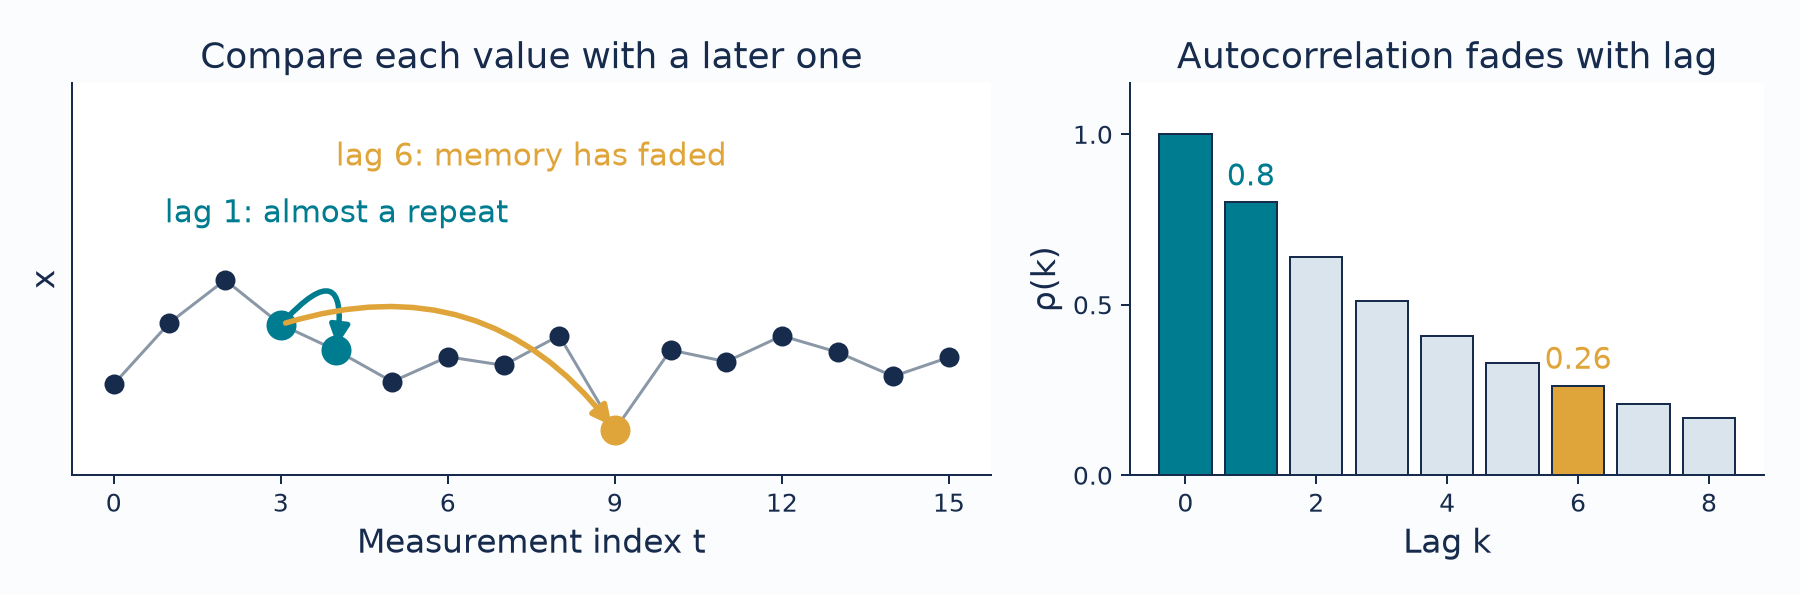

## Scatter at two lags

Plot each value against the value $k$ steps later, for the first 3,000 measurements.

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(7.0, 3.4))
for ax, lag in zip(axes, (1, 20)):
    ax.plot(x[:3000 - lag], x[lag:3000], ".", color="#007c91", alpha=0.25, markersize=4)
    ax.set(title=f"lag {lag}", xlabel="x(t)", ylabel=f"x(t + {lag})", xlim=(-4, 4), ylim=(-4, 4))
    ax.set_aspect("equal")
plt.show()

At lag 1 the points line up along the diagonal: the next value is almost a repeat. At lag 20 the cloud is nearly round: the memory has mostly faded.

## Estimate the autocorrelation

$$\rho(k)=\frac{\operatorname{Cov}(x_t,\,x_{t+k})}{\operatorname{Var}(x)}.$$

- $\rho(k)$ is the exact autocorrelation, a property of the model. For our toy model it is $\rho(k)=r^k$.
- From one run we can only estimate the covariance and the variance from the values we have, so what we compute is an estimate, $\hat\rho(k)\approx\rho(k)$.
- The code mirrors the formula: `covariance` for one lag, `variance`, and `autocorrelation`, which divides one by the other for every lag up to `max_lag`. `exact_autocorrelation` is just $r^k$, for the comparison on the next slide.

In [ ]:
@njit
def variance(values):
    centered = values - values.mean()
    return (centered**2).mean()


@njit
def covariance(values, lag):
    centered = values - values.mean()
    total = 0.0
    for t in range(len(values) - lag):
        total += centered[t] * centered[t + lag]
    return total / len(values)


@njit
def autocorrelation(values, max_lag):
    variance_of_x = variance(values)
    rho = np.empty(max_lag + 1)
    for lag in range(max_lag + 1):
        rho[lag] = covariance(values, lag) / variance_of_x
    return rho


def exact_autocorrelation(r, lags):
    return r**lags

Subtracting the mean inside `covariance` and `variance` matters: without it, a sequence with a nonzero mean would look correlated at every lag. At lag 0 the covariance is the variance, so $\hat\rho(0)=1$.

## Compare with the exact curve

The estimate $\hat\rho(k)$ from our single run against the exact $\rho(k)=r^k$. We keep the estimate as `autocorr_estimate` for the next slides.

In [ ]:
lags = np.arange(121)
autocorr_estimate = autocorrelation(x, max_lag=120)
fig, ax = plt.subplots()
ax.plot(lags, autocorr_estimate, color="#007c91", label="estimate from our run")
ax.plot(lags, exact_autocorrelation(r, lags), "--", color="#a54632", label="exact ρ(k) = $r^k$")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set(xlabel="Lag k (measurements)", ylabel="Autocorrelation")
ax.legend()
plt.show()

The estimate follows $r^k$ closely out to a lag of about 40, then wanders around zero. That noise at large lags is why we'll cap the sum in the next step.

## Count information, not measurements

- If the memory lasts about ten steps, then ten neighboring measurements together are worth about one fresh draw.
- Call that number $g$: how many measurements it takes to carry one independent piece of information.
- The autocorrelation gives it to us, by adding up how much each later measurement still remembers the current one.

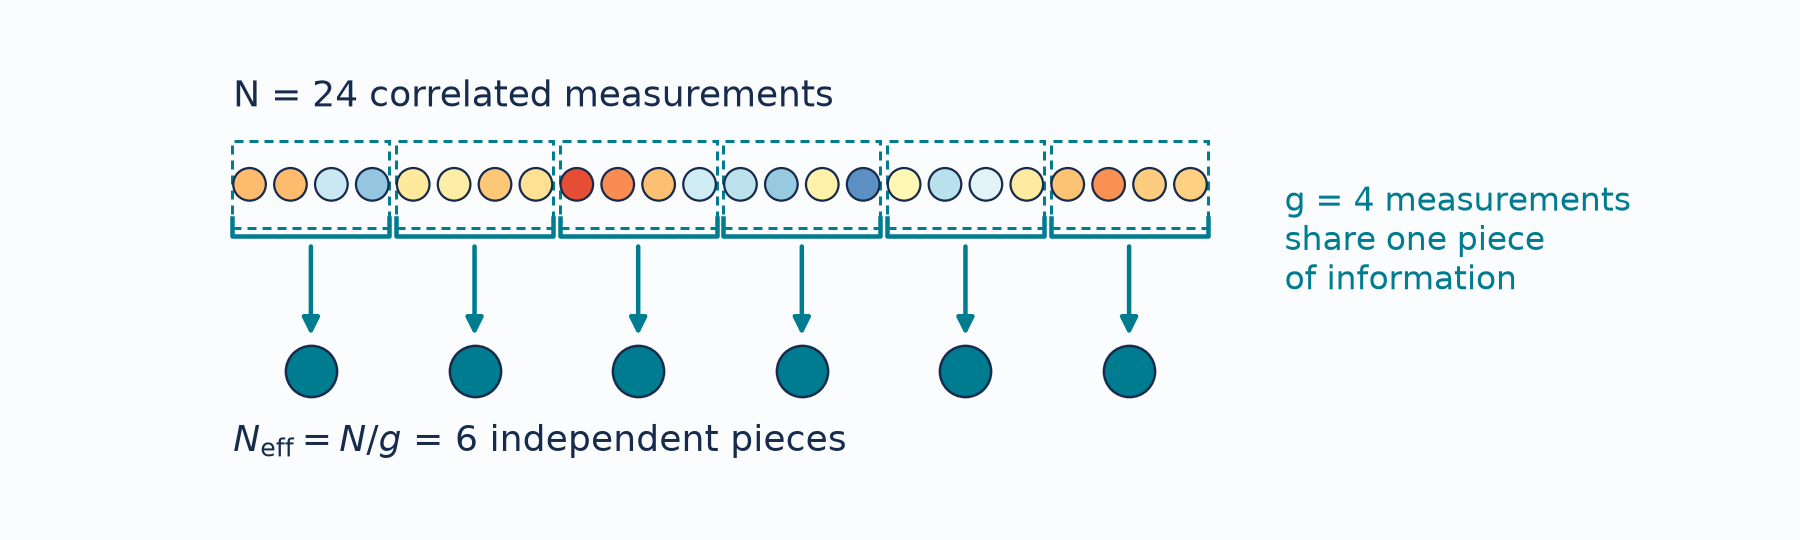

## The effective number of measurements

$$g = 1 + 2\sum_{k\ge 1}\rho(k),\qquad N_{\mathrm{eff}}=\frac{N}{g},\qquad \operatorname{SE}(\bar x)\approx\frac{s}{\sqrt{N_{\mathrm{eff}}}}= s\sqrt{\frac{g}{N}}.$$

- **The 1:** the measurement itself.
- **The sum:** how many later measurements still echo it.
- **The 2:** the memory runs both ways; a measurement resembles the ones before it as much as the ones after it.
- The error bar is the usual formula with $N_{\mathrm{eff}}$, the number of fresh draws, in place of $N$.
- $g/2$ is the **integrated autocorrelation time** $\tau_{\mathrm{int}}$ from lecture; Assignment 3 asks for it in sweeps.
- For our toy model $g=(1+r)/(1-r)=19$ at $r=0.9$. `g_from_autocorrelation` adds up the estimate $\hat\rho(k)$ out to a window; the plot shows the sum growing as the window widens.

In [ ]:
@njit
def g_from_autocorrelation(autocorr_estimate, window):
    total = 0.0
    for lag in range(1, window + 1):
        total += autocorr_estimate[lag]
    return 1 + 2 * total

In [ ]:
windows = np.arange(1, 121)
g_running = np.empty(len(windows))
for i, window in enumerate(windows):
    g_running[i] = g_from_autocorrelation(autocorr_estimate, window)

fig, ax = plt.subplots()
ax.plot(windows, g_running, color="#007c91", label="1 + 2 Σ of the estimated ρ(k), up to the window")
ax.axhline((1 + r) / (1 - r), color="#a54632", linestyle="--", label="exact g = 19")
ax.set(xlabel="Window: largest lag included", ylabel="g")
ax.legend(fontsize=10)
plt.show()

- The sum settles near 19 once the window passes the memory, then wanders as noisy lags are added.
- We'll use a window of 50: just past where the memory ran out in the previous plot, and before the noise piles up.
- Our 32,768 measurements hold about as much information about the mean as 1,700 independent ones.

## An exact reference

- For our toy model the variance of the run mean can be written down exactly for any finite $N$.
- Add the memory $r^{|i-j|}$ between every pair of positions $i$ and $j$ in the run, and divide by $N^2$; `exact_mean_se` does that sum.
- That exact value lets us grade every estimate that follows.

In [ ]:
@njit
def exact_mean_se(n_values, r):
    total = 0.0
    for lag in range(1, n_values):
        total += (1 - lag / n_values) * r**lag
    variance_of_mean = (1 + 2 * total) / n_values
    return np.sqrt(variance_of_mean)

In [ ]:
window = 50
g = g_from_autocorrelation(autocorr_estimate, window)
se_independent = x.std(ddof=1) / np.sqrt(N)
se_corrected = se_independent * np.sqrt(g)
print(f"g from the autocorrelation: {g:.1f}; effective measurements: {N / g:.0f}")
print(f"Mean of the run:            {x.mean():+.4f}")
print(f"Error bar if independent:   {se_independent:.4f}")
print(f"Error bar with g:           {se_corrected:.4f}")
print(f"Exact for our toy model:    {exact_mean_se(N, r):.4f}")

The corrected error bar is about four times the independent one and matches the exact result. A mean that looks like a three-sigma discrepancy from the true value 0 with the independent error bar is less than one sigma away with the corrected one.

## Repeat the experiment

- A standard error predicts how much the mean moves from one run to the next: the width of the heap of run means from the start of the lab.
- For our toy model we can afford to build that heap and check directly.
- `simulate_runs` makes separate runs of our toy model, one after another from the same `distribution`, and keeps only the mean of each.

In [ ]:
@njit
def simulate_runs(n_runs, n_values, r, distribution):
    run_means = np.empty(n_runs)
    for run in range(n_runs):
        run_means[run] = stationary_ar1(n_values, r, distribution).mean()
    return run_means

Only the means come back; the sequences themselves are thrown away. Compiled, the next slide's two million steps take a fraction of a second.

## The heap of run means

- 500 runs of 4,096 values each. The histogram is the heap of their means.
- The two curves are Gaussians with the widths the two error bars predict: $s/\sqrt N$ if the values were independent, and $s\sqrt{g/N}$ with $g=19$.

In [ ]:
n_runs, n_values = 500, 4096
run_means = simulate_runs(n_runs, n_values, r, np.random.default_rng(7))

fig, ax = plt.subplots()
ax.hist(run_means, bins=30, density=True, color="#9fc9d3", label="500 run means")
grid = np.linspace(-0.3, 0.3, 300)
ax.plot(grid, norm.pdf(grid, scale=1 / np.sqrt(n_values)), color="#a54632", label="if independent: s/√N")
ax.plot(grid, norm.pdf(grid, scale=np.sqrt(19 / n_values)), color="#007c91", label="with g = 19: s√(g/N)")
ax.set(xlabel="Mean of one run", ylabel="Density", xlim=(-0.3, 0.3))
ax.legend(fontsize=10)
plt.show()

The run means spread as the corrected formula predicts, not as the independent one does. This is what an error bar means: the width of this histogram.

## Blocking: average inside blocks first

- Cut the sequence into consecutive blocks and average each one.
- A block mean remembers the previous block only through the few measurements at its edge.
- So once the blocks are much longer than the memory, the block means are nearly fresh draws and the ordinary formula applies to them.
- This is the error bar Assignment 3 asks for.

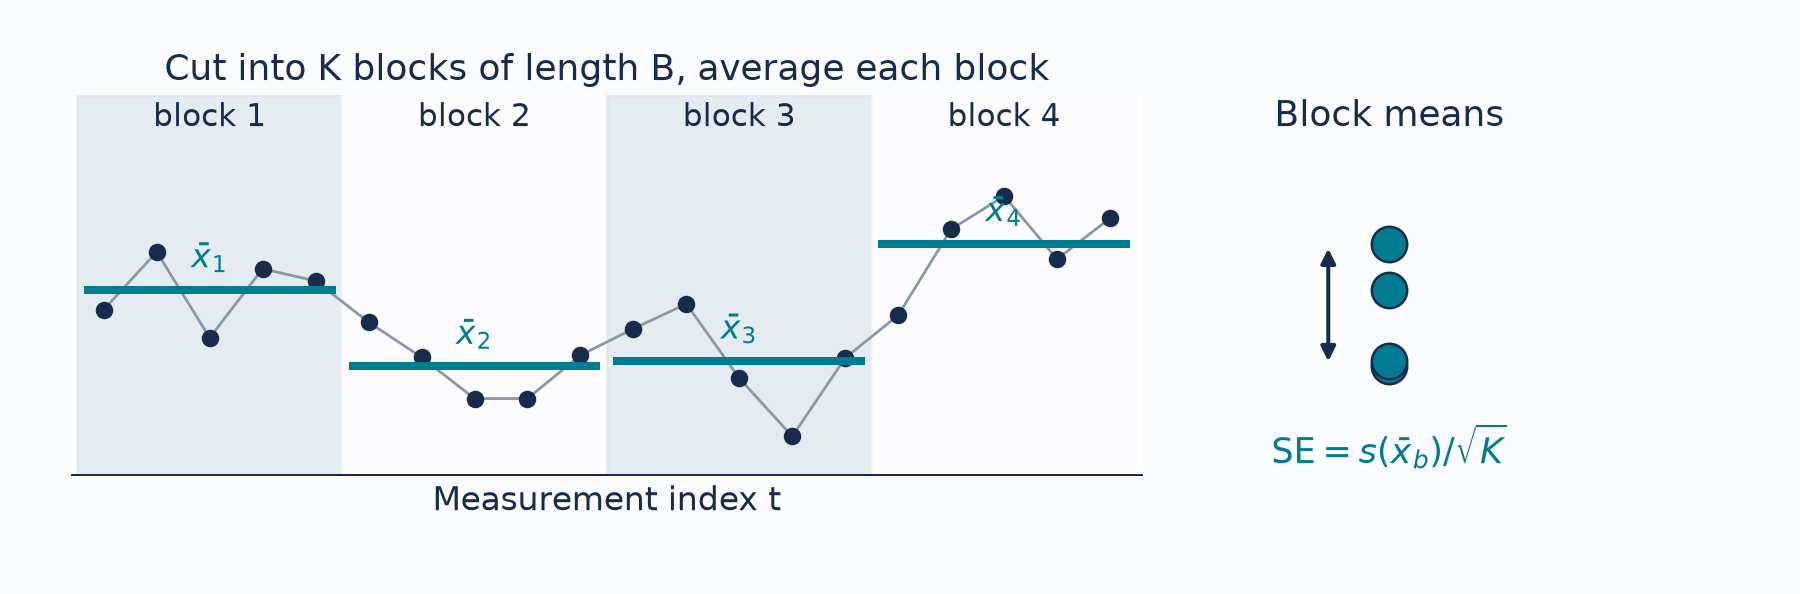

## Block means on the trace

- `block_means` cuts a sequence into blocks of `block_length` values and averages each block.
- The first 1,024 measurements in blocks of 64; each horizontal bar is one block mean.

In [ ]:
@njit
def block_means(values, block_length):
    n_blocks = len(values) // block_length
    means = np.empty(n_blocks)
    for block in range(n_blocks):
        means[block] = values[block * block_length:(block + 1) * block_length].mean()
    return means

In [ ]:
block_length = 64
segment = x[:1024]
means = block_means(segment, block_length)
fig, ax = plt.subplots()
ax.plot(segment, color="#8a97a6", linewidth=0.8, label="measurements")
ax.step(np.arange(0, 1024, block_length), means, where="post", color="#007c91",
        linewidth=2.5, label=f"block means, B = {block_length}")
ax.set(xlabel="Measurement index t", ylabel="x")
ax.legend(fontsize=10)
plt.show()

The block means still wander, but each one summarizes 64 measurements, three times the memory length, so neighboring block means are nearly independent.

## The blocking curve

$$\operatorname{SE}(\bar x)\approx\frac{s(\bar x_1,\ldots,\bar x_K)}{\sqrt K},\qquad K=\frac{N}{B}.$$

- $B$ is the block length, $K$ the number of blocks, and $s(\bar x_1,\ldots,\bar x_K)$ the spread of the $K$ block means.
- `blocking_curve` repeats this for block lengths from 1 to 1,024; we'll use it again on the Ising run.
- No autocorrelation function is needed; the block length does the work.

In [ ]:
def blocking_curve(values, block_lengths):
    errors = np.empty(len(block_lengths))
    for i, block_length in enumerate(block_lengths):
        means = block_means(values, block_length)
        errors[i] = means.std(ddof=1) / np.sqrt(len(means))
    return errors

In [ ]:
block_lengths = 2 ** np.arange(0, 11)
blocked_errors = blocking_curve(x, block_lengths)

fig, ax = plt.subplots()
ax.semilogx(block_lengths, blocked_errors, "o-", base=2, color="#007c91", label="blocked estimate")
ax.axhline(exact_mean_se(N, r), color="#a54632", linestyle="--", label="exact")
ax.set(xlabel="Block length B", ylabel="Standard error of the mean")
ax.legend()
plt.show()

- At $B=1$ this is the independent formula.
- The estimate grows as the blocks absorb the memory and levels off near the exact value.
- Blocks of 256 to 1,024 still leave 128 to 32 block means to average; the plateau is where to read off the error bar.

## Which route, and how long a block?

- Two routes to the same error bar: measure the memory, with $g$ from the autocorrelation, or hide it, with blocks.
- Blocking needs no autocorrelation function and no window to choose, so it is the everyday tool. The autocorrelation is how we understand what blocking is doing.
- Either route gives $\tau_{\mathrm{int}}$: from $g$ directly, or from the blocking curve, since the plateau divided by the $B=1$ value, squared, is $g$.
- How long a block? Longer than the memory, so a few times the lag where the autocorrelation reaches zero. In practice read it off the curve: increase $B$ until the estimate stops growing, and stop while enough blocks remain.

## A result built from two averages

$$\widehat V=\overline{x^2}-\bar x^{\,2}\approx\operatorname{Var}(x).$$

- So far we have put error bars on a plain average.
- The variance is different: it combines two averages of the same data, the mean of $x^2$ and the square of the mean of $x$.
- The Ising susceptibility, $\chi=\frac{N_s}{T}\left(\langle m^2\rangle-\langle m\rangle^2\right)$, which measures how strongly the magnetization fluctuates, has the same shape, and so does the heat capacity.
- The rest of the lab is about error bars for results like these.
- The first step is to keep both $\overline{x}_b$ and $\overline{x^2}_b$ for each block: `block_means_and_squares` returns one row per block.

In [ ]:
@njit
def block_means_and_squares(values, block_length):
    n_blocks = len(values) // block_length
    rows = np.empty((n_blocks, 2))
    for block in range(n_blocks):
        piece = values[block * block_length:(block + 1) * block_length]
        rows[block, 0] = piece.mean()
        rows[block, 1] = (piece**2).mean()
    return rows


def variance_statistic(pair):
    mean_x, mean_of_squares = pair
    return mean_of_squares - mean_x**2

In [ ]:
block_length = 256
blocks = block_means_and_squares(x, block_length)
n_blocks = len(blocks)
variance_estimate = variance_statistic(blocks.mean(axis=0))
print(f"{n_blocks} blocks of {block_length} measurements")
print(f"Estimated variance: {variance_estimate:.4f} (true value 1)")

- Each row of `blocks` is one block: its mean and its mean square.
- The estimate comes from the column averages, `blocks.mean(axis=0)`: one pair for the whole run.
- `variance_statistic` turns a pair into the variance. Now we need its error bar.

## Why not the usual formula?

- For a plain mean, blocking and $s/\sqrt K$ were enough.
- $\widehat V$ is not a plain mean: it combines two averages, and their errors are linked because both come from the same data.
- Pushing two error bars through the formula is messy, and it only gets worse for more complicated results.
- So we won't derive a formula. We'll make many slightly different versions of the data set, compute $\widehat V$ on each, and watch how much the answer moves.
- The jackknife and the bootstrap are two recipes for making those versions.
- Both work on the blocks from the last section, so the memory stays inside each block.

## Jackknife: leave one block out

- Drop one block, recompute $\widehat V$ from the rest, and repeat for every block.
- The $K$ recomputed values, called **replicates**, differ only slightly, because each one still uses almost all the data.

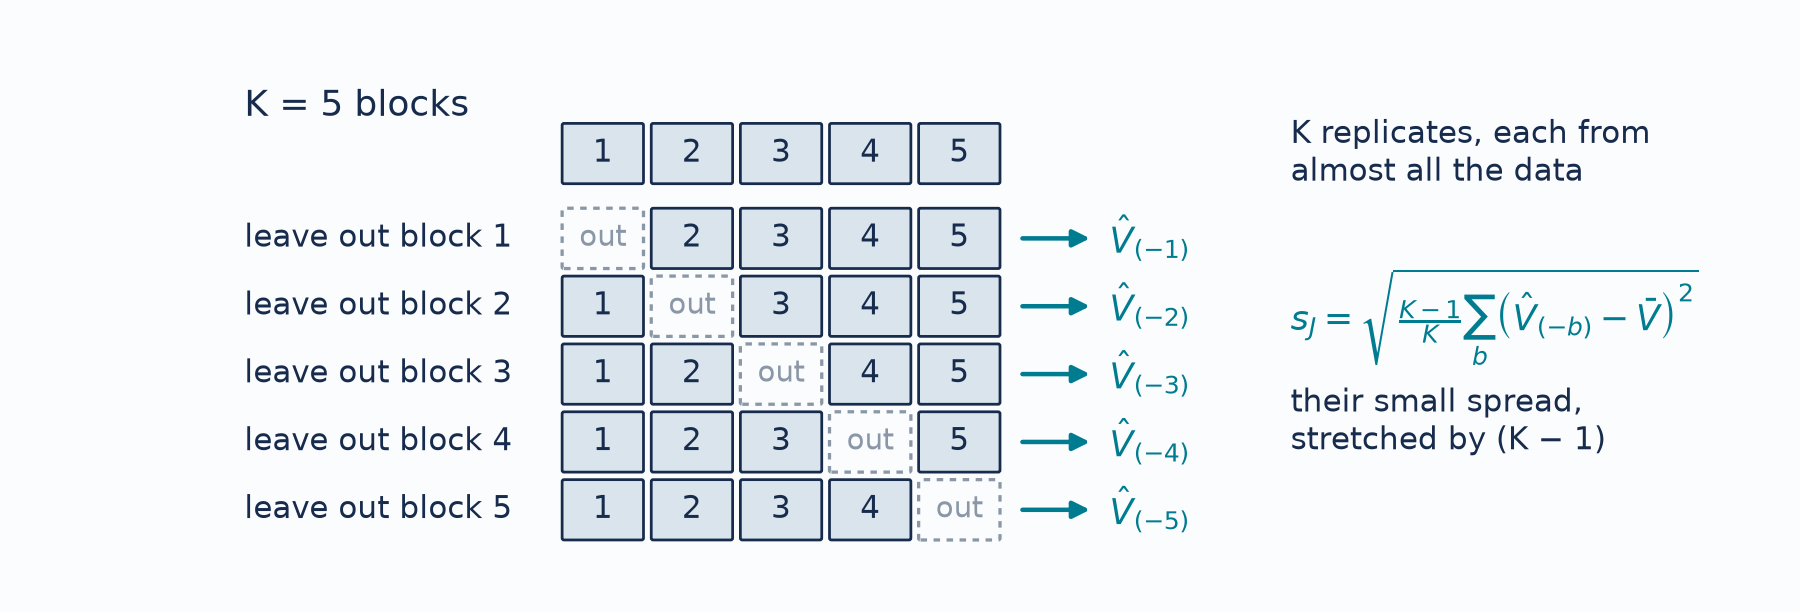

## The jackknife function

$$s_J=\sqrt{\frac{K-1}{K}\sum_{b=1}^{K}\bigl(\widehat V_{(-b)}-\overline{V}\bigr)^2}.$$

- $\widehat V_{(-b)}$ is the replicate with block $b$ left out; $\overline V$ is the average of the replicates.
- The loop leaves out one block, applies the statistic to the averages of the rest, and moves on to the next block.
- Leaving out one block of $K$ barely changes the answer, so the replicates huddle together.
- The factor $K-1$ scales that huddle up to the spread the answer would have across independent runs.

In [ ]:
def jackknife(blocks, statistic):
    n_blocks = len(blocks)
    replicates = np.empty(n_blocks)
    for block in range(n_blocks):
        others = np.delete(blocks, block, axis=0)
        replicates[block] = statistic(others.mean(axis=0))
    error = np.sqrt((n_blocks - 1) / n_blocks * np.sum((replicates - replicates.mean())**2))
    return statistic(blocks.mean(axis=0)), error, replicates

`np.delete` drops row $b$ of the table; the statistic is applied to the column averages of the remaining $K-1$ rows, and the loop repeats for every block.

## The jackknife replicates

The $K=128$ replicates of the variance, each with one block removed.

In [ ]:
estimate, se_jackknife, replicates = jackknife(blocks, variance_statistic)
print(f"Variance = {estimate:.4f} ± {se_jackknife:.4f} (block jackknife)")
fig, ax = plt.subplots()
ax.plot(replicates, "o", color="#007c91", markersize=4, label="leave-one-block-out replicates")
ax.axhline(estimate, color="#a54632", linestyle="--", label="full-sample estimate")
ax.set(xlabel="Left-out block b", ylabel="Variance estimate")
ax.legend(fontsize=10)
plt.show()

The replicates sit within about $0.01$ of the estimate, yet the error bar is $0.024$: the $K-1$ factor does that stretching.

## Bootstrap: draw blocks with replacement

- Draw $K$ blocks at random **with replacement**: some appear twice, some not at all.
- Recompute $\widehat V$, repeat two thousand times, and take the spread of the replicates.

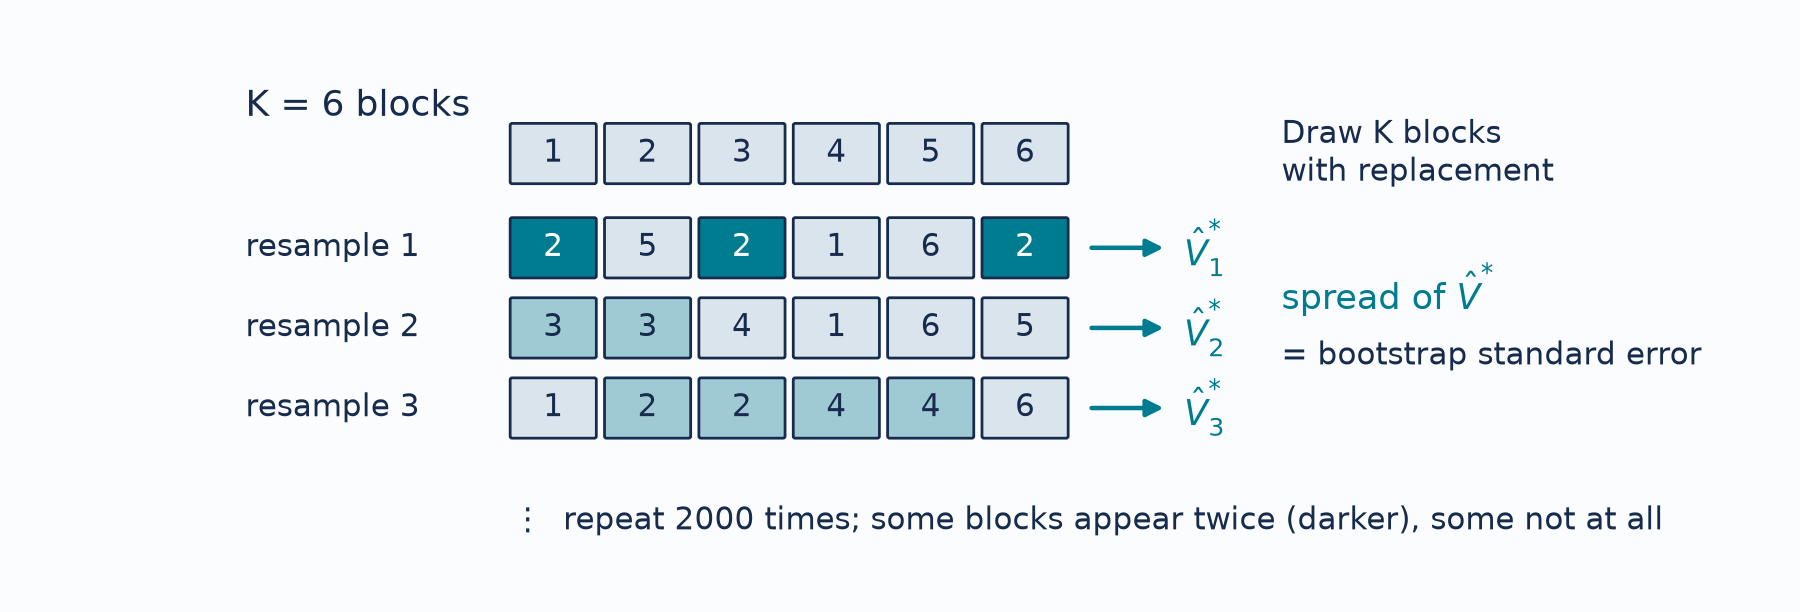

## The bootstrap function

- Drawing whole rows keeps $\overline{x}_b$ and $\overline{x^2}_b$ together.
- Drawing blocks rather than single measurements keeps the memory inside each block.

In [ ]:
def bootstrap(blocks, statistic, n_resamples, seed):
    distribution = np.random.default_rng(seed)
    n_blocks = len(blocks)
    estimates = np.empty(n_resamples)
    for resample in range(n_resamples):
        chosen = distribution.integers(0, n_blocks, size=n_blocks)
        estimates[resample] = statistic(blocks[chosen].mean(axis=0))
    return estimates

`distribution.integers(0, n_blocks, size=n_blocks)` draws $K$ block numbers with replacement; `blocks[chosen]` assembles the resampled table in one indexing step, and its column averages go to the statistic.

## The bootstrap distribution

- Two thousand resamples of the 128 blocks.
- `plot_resamples`, from the setup cell, draws the histogram of the replicates and puts the jackknife result on top as an actual error bar.

In [ ]:
bootstrap_values = bootstrap(blocks, variance_statistic, n_resamples=2000, seed=314)
se_bootstrap = bootstrap_values.std(ddof=1)
print(f"Variance = {variance_estimate:.4f} ± {se_bootstrap:.4f} (block bootstrap)")
plot_resamples(bootstrap_values, variance_estimate, se_jackknife,
               "Resampled variance estimate", "2000 bootstrap replicates")

The two methods agree: the width of the bootstrap histogram matches the jackknife error bar drawn on top of it. The jackknife is deterministic and cheap; the bootstrap also shows the shape of the uncertainty.

## Why we resample blocks

- Resampling single measurements shuffles them, which removes the memory that makes the mean uncertain.
- The resampled sets look more independent than the run, and the replicates spread too little.

In [ ]:
single_values = bootstrap(block_means_and_squares(x, 1), variance_statistic, n_resamples=400, seed=2718)
print(f"Error bar from single measurements: {single_values.std(ddof=1):.4f}")
print(f"Error bar from blocks of {block_length}:       {se_bootstrap:.4f}")
fig, ax = plt.subplots()
ax.hist(single_values, bins=30, density=True, color="#e0b35a", alpha=0.85, label="resample single measurements")
ax.hist(bootstrap_values, bins=40, density=True, color="#9fc9d3", alpha=0.85, label=f"resample blocks of {block_length}")
ax.set(xlabel="Resampled variance estimate", ylabel="Density")
ax.legend(fontsize=10)
plt.show()

The single-measurement bootstrap is three times too narrow. Blocks of 256 keep the memory and recover the full width.

## Back to the Ising run

- Now the same tools on yesterday's magnetization.
- First question: how long is its memory, and how does that change with temperature?
- Three runs of 4,096 sweeps after 512 sweeps of burn-in, at $T=3$, $2.7$, and $2.5$, with a snapshot of the lattice every 64 sweeps for the next slide.

In [ ]:
temperatures = (3.0, 2.7, 2.5)
snapshot_every = 64
snapshot_runs = {}
fig, ax = plt.subplots()
for temperature, color in zip(temperatures, ("#007c91", "#e0a53a", "#a54632")):
    final, m_history_T, snapshots_T = run_ising(temperature, N_LATTICE, 512 + 4096, seed=142,
                                                 record_every=snapshot_every)
    snapshot_runs[temperature] = snapshots_T
    ax.plot(autocorrelation(m_history_T[513:], 300), color=color, label=f"T = {temperature}")
ax.axhline(0, color="gray", linewidth=0.8)
ax.set(xlabel="Lag (sweeps)", ylabel="Autocorrelation of m")
ax.legend()
plt.show()

- At $T=3$ the memory lasts a few dozen sweeps.
- At $T=2.5$ it lasts hundreds, and a run of 4,096 sweeps contains only a handful of independent configurations.
- This is **critical slowing down**: the closer the temperature is to the transition, the longer the chain takes to forget where it was, so each sweep adds less new information.
- It is why Assignment 3 asks about run length near $T_{\mathrm c}$.

## The configurations behind the curves

- The saved snapshots of those three runs, one every 64 sweeps, played as an animation from the all-up start.
- `draw_frame` swaps the snapshot for one frame into each of the three images.
- Press play. The last frame is the final lattice of each run.

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(6.6, 2.6))
images = [show_lattice(axis, snapshot_runs[temperature][0], f"T = {temperature:g}")
          for axis, temperature in zip(axes, temperatures)]
n_frames = len(snapshot_runs[temperatures[0]])


def draw_frame(frame):
    for image, temperature in zip(images, temperatures):
        image.set_data(snapshot_runs[temperature][frame])
    fig.suptitle(f"Sweep {frame * snapshot_every}", fontsize=11)
    return images


animation = FuncAnimation(fig, draw_frame, frames=n_frames, interval=120)
plt.close(fig)
HTML(animation.to_jshtml())

Larger aligned patches take longer to rearrange one flip at a time, and the memory of $m$ grows with them. Watch the $T=2.5$ run keep its large patches for hundreds of sweeps while $T=3$ reshuffles within a few.

## Block the magnetization

- The same `blocking_curve` as before, now on $m$ at $T=2.7$ over the 16,384 recorded sweeps.
- Block lengths from 1 to 2,048 sweeps.

In [ ]:
block_lengths = 2 ** np.arange(0, 12)
blocked_errors = blocking_curve(m_run, block_lengths)

fig, ax = plt.subplots()
ax.semilogx(block_lengths, blocked_errors, "o-", base=2, color="#007c91")
ax.set(xlabel="Block length B (sweeps)", ylabel="Standard error of the mean m",
       title=f"T = {T}, {len(m_run):,} sweeps")
plt.show()
print(f"Mean m = {m_run.mean():+.4f} ± {blocked_errors[9]:.4f} (blocks of {block_lengths[9]} sweeps)")
print(f"Error bar if independent: {m_run.std(ddof=1) / np.sqrt(len(m_run)):.4f}")

The error bar levels off once the blocks are a few hundred sweeps long, at seven times the independent value. This is exactly the blocking error bar Assignment 3 asks for, there on $\langle x^2\rangle$ of a path.

## The susceptibility with an error bar

- The susceptibility per spin, $\chi=\frac{N_s}{T}\left(\langle m^2\rangle-\langle m\rangle^2\right)$, is our two-average statistic.
- Block the pairs $[\overline m_b,\overline{m^2}_b]$ and hand the complete expression to the jackknife and the bootstrap.
- Same `plot_resamples` picture as for the variance.

In [ ]:
N_SPINS = N_LATTICE**2

def susceptibility(pair):
    return N_SPINS / T * variance_statistic(pair)

In [ ]:
pairs = block_means_and_squares(m_run, 512)
chi, chi_jackknife, _ = jackknife(pairs, susceptibility)
chi_bootstrap = bootstrap(pairs, susceptibility, n_resamples=2000, seed=11)
print(f"{len(pairs)} blocks of 512 sweeps at T = {T}")
print(f"χ = {chi:.2f} ± {chi_jackknife:.2f} (jackknife)")
print(f"χ = {chi:.2f} ± {chi_bootstrap.std(ddof=1):.2f} (bootstrap)")
plot_resamples(chi_bootstrap, chi, chi_jackknife, "Susceptibility per spin χ", "bootstrap replicates")

Thirty-two blocks are enough for a six-percent error bar, and the two methods agree. The same three lines give an error bar for any quantity built from block averages.

## Where you'll use this

- **Assignment 3, Ising part:** $m$ against temperature with an error bar or band at each $T$, from blocked block means, and a run length chosen after looking at the autocorrelation near $T_{\mathrm c}$.
- **Assignment 3, path-integral part:** the time series of $\frac1N\sum_i x_i^2$, its autocorrelation, $\tau_{\mathrm{int}}$ in sweeps, and $\langle x^2\rangle$ with a blocking error bar next to the naive one, compared with the exact $\tfrac12\coth(\beta/2)$.
- **Final projects:** every Monte Carlo error bar must account for autocorrelation, by blocking or by $\tau_{\mathrm{int}}$.

The exact result is the test of your simulation. The error bar decides whether you passed it.

## From one run to an honest error bar

- We measured the memory of a sequence with its autocorrelation and counted its information as $N/g$.
- Blocking turned correlated measurements into nearly independent units.
- The jackknife and bootstrap put error bars on a result built from two averages.
- For any Monte Carlo run: inspect the trace and its autocorrelation, choose a block length past the memory, resample blocks, and report the estimate with its error, the run length, and the block length you used.

### References

- [Charles Geyer: MCMC and batch means](https://www.stat.umn.edu/geyer/5421/notes/mcmc-bayes.html).
- [Weigel and Janke: Error estimation and reduction with cross correlations](https://arxiv.org/abs/1002.4517), especially the jackknife treatment of correlated estimates.
- [Cosma Shalizi: Bootstrap](https://www.stat.cmu.edu/~cshalizi/dst/20/lectures/16/lecture-16.html).
- [Anders Sandvik: Monte Carlo methods](https://physics.bu.edu/~py502/lectures5/mc.pdf), for fluctuation observables in spin simulations.